# Notebook 06 - Model Interpretation and SHAP

Scope: explain completed modeling results using existing interpretation CSVs plus an interpretation-only XGBoost recreation for SHAP. The recreated XGBoost model is fitted only to reproduce a compatible model object for explanation; it is not used for model selection, threshold tuning, or changing Notebook 05 comparison results.

## 1. Imports

In [1]:
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from IPython.display import display
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=UserWarning)

RANDOM_STATE = 42
TOP_N_FEATURES = 15
SHAP_SAMPLE_SIZE = 500
EXPECTED_TREE_DIMS = {
    'train': (4930, 20),
    'validation': (1056, 20),
    'test': (1057, 20),
}
EXPECTED_X_DIMS = {
    'train': (4930, 18),
    'validation': (1056, 18),
    'test': (1057, 18),
}
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120

## 2. Path Setup

In [2]:
def find_refactor_root(start_path: Path) -> Path:
    current = start_path.resolve()
    for candidate in [current, *current.parents]:
        if candidate.name == 'churn_pipeline_v2':
            return candidate
        nested = candidate / 'churn_pipeline_v2'
        if nested.exists() and nested.is_dir():
            return nested.resolve()
    raise FileNotFoundError('Could not locate churn_pipeline_v2 from the current working directory.')


CURRENT_WORKING_DIRECTORY = Path.cwd().resolve()
REFACTOR_ROOT = find_refactor_root(CURRENT_WORKING_DIRECTORY)
REPO_ROOT = REFACTOR_ROOT.parent
TARGET_NOTEBOOK_PATH = REFACTOR_ROOT / 'notebooks' / '06_Model_Interpretation_SHAP.ipynb'

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from churn_pipeline_v2.src.path import DATA_REPORTS_DIR, FIGURES_DIR
from churn_pipeline_v2.src.utils.feature_display import build_feature_mapping_table

DATA_REPORTS_DIR = Path(DATA_REPORTS_DIR)
FIGURES_DIR = Path(FIGURES_DIR)

path_checks = pd.DataFrame([
    {'Name': 'Current working directory', 'Path': CURRENT_WORKING_DIRECTORY, 'Exists': CURRENT_WORKING_DIRECTORY.exists()},
    {'Name': 'Refactor root', 'Path': REFACTOR_ROOT, 'Exists': REFACTOR_ROOT.exists()},
    {'Name': 'Target notebook', 'Path': TARGET_NOTEBOOK_PATH, 'Exists': TARGET_NOTEBOOK_PATH.exists()},
    {'Name': 'Data reports folder', 'Path': DATA_REPORTS_DIR, 'Exists': DATA_REPORTS_DIR.exists()},
    {'Name': 'Figures folder', 'Path': FIGURES_DIR, 'Exists': FIGURES_DIR.exists()},
])
display(path_checks)
if not DATA_REPORTS_DIR.exists() or not FIGURES_DIR.exists():
    raise FileNotFoundError('Required refactor output folders are missing.')

,Name,Path,Exists
0,Current working directory,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
1,Refactor root,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
2,Target notebook,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
3,Data reports folder,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
4,Figures folder,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True


## 3. Helper Functions

In [3]:
def load_required_csv(filename: str) -> pd.DataFrame:
    path = DATA_REPORTS_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f'Missing required interpretation input: {path}')
    df = pd.read_csv(path)
    print(f'Loaded {filename}: shape={df.shape}')
    return df


def display_and_save_table(df: pd.DataFrame, filename: str, title: str) -> Path:
    path = DATA_REPORTS_DIR / filename
    df.to_csv(path, index=False)
    print(title)
    display(df)
    print(f'Table shape: {df.shape}')
    print(f'Saved table: {path}')
    return path


def save_current_figure(filename: str, tight: bool = True) -> Path:
    path = FIGURES_DIR / filename
    if tight:
        try:
            plt.tight_layout()
        except Exception:
            pass
    plt.savefig(path, dpi=160, bbox_inches='tight')
    print(f'Saved figure: {path}')
    display(plt.gcf())
    plt.close()
    return path


def standardize_driver_group(row: pd.Series) -> str:
    text = ' '.join(str(row.get(column, '')) for column in ['Feature_Code', 'Feature_Display_Name', 'Base_Feature', 'Feature_Group']).lower()
    if 'contract' in text:
        return 'Contract type'
    if 'tenure' in text:
        return 'Tenure'
    if 'internet' in text:
        return 'Internet service'
    if 'tech support' in text or 'online security' in text or 'security' in text:
        return 'Tech support / online security'
    if 'monthly' in text or 'total charges' in text or 'charge' in text:
        return 'Monthly charges / total charges'
    if 'payment' in text:
        return 'Payment method'
    if 'service diversity' in text:
        return 'Service diversity'
    if 'paperless' in text:
        return 'Paperless billing'
    return 'Other customer or service profile'


def plot_horizontal_bar(df: pd.DataFrame, value_col: str, label_col: str, title: str, xlabel: str, filename: str, color: str = '#3563a8') -> Path:
    plot_df = df.head(TOP_N_FEATURES).iloc[::-1].copy()
    height = max(6, len(plot_df) * 0.45)
    fig, ax = plt.subplots(figsize=(10, height))
    ax.barh(plot_df[label_col], plot_df[value_col], color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('')
    ax.grid(axis='x', alpha=0.25)
    return save_current_figure(filename)


def build_business_driver_rows(df: pd.DataFrame, method: str, value_col: str, value_unit: str, top_n: int = 10) -> pd.DataFrame:
    rows = df.head(top_n).copy()
    rows['Method'] = method
    rows['Value'] = rows[value_col]
    rows['Value_Unit'] = value_unit
    rows['Driver_Group'] = rows.apply(standardize_driver_group, axis=1)
    rows['Interpretation_Note'] = f'{method}; values are not directly comparable across methods.'
    return rows[['Method', 'Feature_Code', 'Feature_Display_Name', 'Driver_Group', 'Value', 'Value_Unit', 'Rank', 'Interpretation_Note']]

## 4. Load Existing Coefficient and Feature-Importance CSVs

In [4]:
logistic_coefficients = load_required_csv('logistic_coefficients.csv')
logistic_top_absolute = load_required_csv('logistic_top_absolute_coefficients.csv')
logistic_top_positive = load_required_csv('logistic_top_positive_coefficients.csv')
logistic_top_negative = load_required_csv('logistic_top_negative_coefficients.csv')
random_forest_importance = load_required_csv('random_forest_feature_importance.csv')
random_forest_top_importance = load_required_csv('random_forest_top_feature_importance.csv')
xgboost_importance = load_required_csv('xgboost_feature_importance.csv')
xgboost_top_importance = load_required_csv('xgboost_top_feature_importance.csv')
feature_mapping_logistic = load_required_csv('feature_name_mapping_logistic.csv')
feature_mapping_tree = load_required_csv('feature_name_mapping_tree.csv')
feature_mapping_xgboost = load_required_csv('feature_name_mapping_xgboost.csv')
feature_mapping_reference = load_required_csv('feature_name_mapping_reference.csv')
best_model_summary = load_required_csv('core_model_best_model_summary.csv')

required_inputs = [
    logistic_coefficients,
    logistic_top_absolute,
    logistic_top_positive,
    logistic_top_negative,
    random_forest_importance,
    random_forest_top_importance,
    xgboost_importance,
    xgboost_top_importance,
    feature_mapping_xgboost,
]
if any(df.empty for df in required_inputs):
    raise ValueError('One or more interpretation input tables are empty.')

Loaded logistic_coefficients.csv: shape=(26, 16)
Loaded logistic_top_absolute_coefficients.csv: shape=(15, 16)
Loaded logistic_top_positive_coefficients.csv: shape=(10, 16)
Loaded logistic_top_negative_coefficients.csv: shape=(10, 16)
Loaded random_forest_feature_importance.csv: shape=(18, 10)
Loaded random_forest_top_feature_importance.csv: shape=(15, 10)
Loaded xgboost_feature_importance.csv: shape=(18, 10)
Loaded xgboost_top_feature_importance.csv: shape=(15, 10)
Loaded feature_name_mapping_logistic.csv: shape=(26, 9)
Loaded feature_name_mapping_tree.csv: shape=(18, 9)
Loaded feature_name_mapping_xgboost.csv: shape=(18, 9)
Loaded feature_name_mapping_reference.csv: shape=(18, 8)
Loaded core_model_best_model_summary.csv: shape=(6, 4)


## 5. Logistic Regression Coefficient Interpretation

Logistic Regression coefficient interpretation summary


,Feature_Code,Feature_Display_Name,Coefficient,Abs_Coefficient,Direction,Rank,Driver_Group
0,TotalCharges,Total Charges,-0.766378,0.766378,decreases churn probability,1,Monthly charges / total charges
1,Contract_24,Contract Type = Two year,-0.683150,0.683150,decreases churn probability,2,Contract type
2,Dependents_Yes,Dependents = Yes,-0.649922,0.649922,decreases churn probability,3,Other customer or service profile
3,InternetService_No,Internet Service = No Internet Service,-0.378273,0.378273,decreases churn probability,4,Internet service
4,Contract_12,Contract Type = One year,-0.336179,0.336179,decreases churn probability,5,Contract type
5,MonthlyCharges,Monthly Charges,0.334798,0.334798,increases churn probability,6,Monthly charges / total charges
6,monthly_charges_ratio,Monthly Charges Ratio,0.334798,0.334798,increases churn probability,7,Monthly charges / total charges
7,PaperlessBilling_1,Paperless Billing = Yes,0.236857,0.236857,increases churn probability,8,Paperless billing
8,Tenure,Tenure,-0.208399,0.208399,decreases churn probability,9,Contract type
9,InternetService_Fiber optic,Internet Service = Fiber optic,0.159882,0.159882,increases churn probability,10,Internet service


Table shape: (26, 7)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_logistic_coefficients_summary.csv
Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_01_logistic_top_coefficients.png


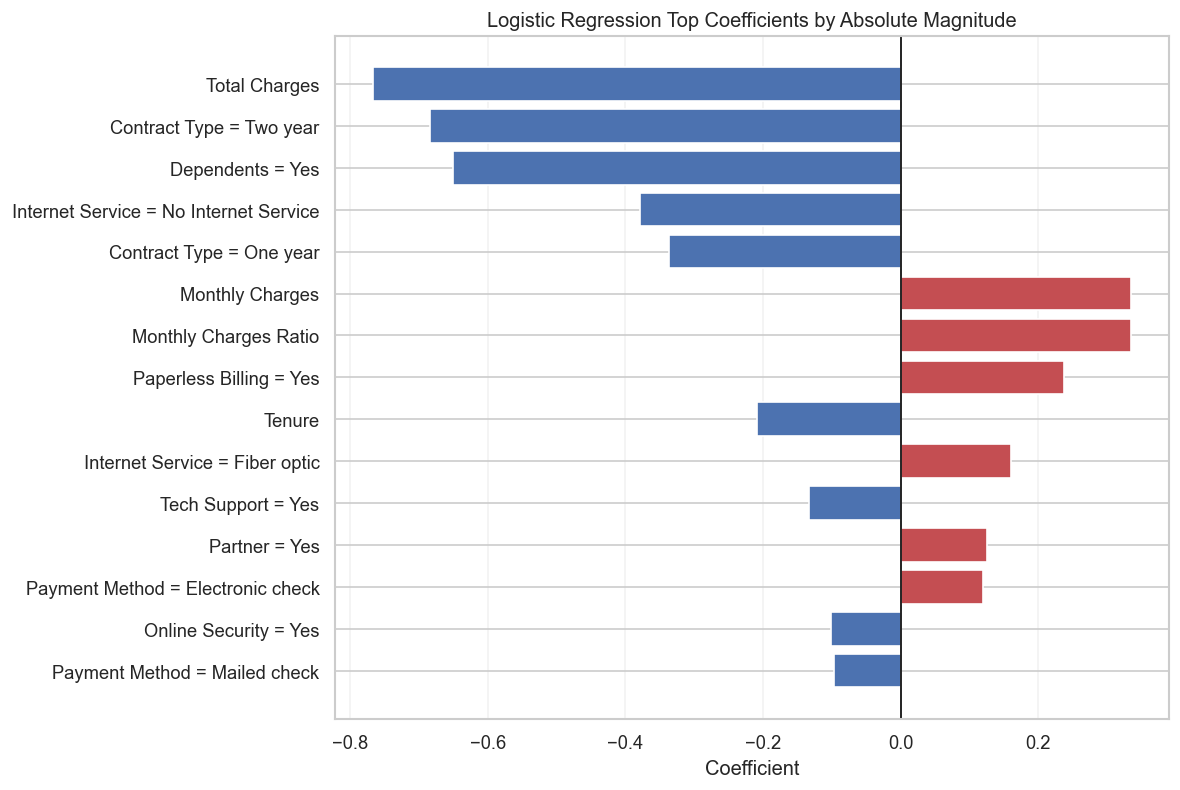

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/model_interpretation_01_logistic_top_coefficients.png')

In [5]:
logistic_summary = logistic_coefficients.copy()
if 'Abs_Coefficient' not in logistic_summary.columns:
    logistic_summary['Abs_Coefficient'] = logistic_summary['Coefficient'].abs()
if 'Direction' not in logistic_summary.columns:
    logistic_summary['Direction'] = np.where(logistic_summary['Coefficient'] >= 0, 'Positive', 'Negative')
logistic_summary = logistic_summary.sort_values('Abs_Coefficient', ascending=False).reset_index(drop=True)
logistic_summary['Rank'] = np.arange(1, len(logistic_summary) + 1)
logistic_summary['Driver_Group'] = logistic_summary.apply(standardize_driver_group, axis=1)
logistic_output_columns = ['Feature_Code', 'Feature_Display_Name', 'Coefficient', 'Abs_Coefficient', 'Direction', 'Rank', 'Driver_Group']
logistic_coefficients_summary = logistic_summary[logistic_output_columns].copy()
display_and_save_table(
    logistic_coefficients_summary,
    'model_interpretation_logistic_coefficients_summary.csv',
    'Logistic Regression coefficient interpretation summary',
)

plot_df = logistic_coefficients_summary.head(TOP_N_FEATURES).iloc[::-1].copy()
colors = np.where(plot_df['Coefficient'] >= 0, '#C44E52', '#4C72B0')
fig, ax = plt.subplots(figsize=(10, max(6, len(plot_df) * 0.45)))
ax.barh(plot_df['Feature_Display_Name'], plot_df['Coefficient'], color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Logistic Regression Top Coefficients by Absolute Magnitude')
ax.set_xlabel('Coefficient')
ax.set_ylabel('')
ax.grid(axis='x', alpha=0.25)
save_current_figure('model_interpretation_01_logistic_top_coefficients.png')

## 6. Random Forest Feature Importance Interpretation

Random Forest native feature importance summary


,Feature_Code,Feature_Display_Name,Importance,Rank,Driver_Group
0,TotalCharges,Total Charges,0.139764,1,Monthly charges / total charges
1,monthly_charges_ratio,Monthly Charges Ratio,0.136337,2,Monthly charges / total charges
2,MonthlyCharges,Monthly Charges,0.135226,3,Monthly charges / total charges
3,Tenure,Tenure,0.124372,4,Contract type
4,Contract,Contract Type,0.121987,5,Contract type
5,tenure_group,Tenure Group,0.053841,6,Tenure
6,Dependents,Dependents,0.049052,7,Other customer or service profile
7,PaymentMethod,Payment Method,0.040458,8,Payment method
8,InternetService,Internet Service,0.038583,9,Internet service
9,service_diversity,Service Diversity Score,0.034653,10,Service diversity


Table shape: (15, 5)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_random_forest_top_features.csv
Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_02_random_forest_top_importance.png


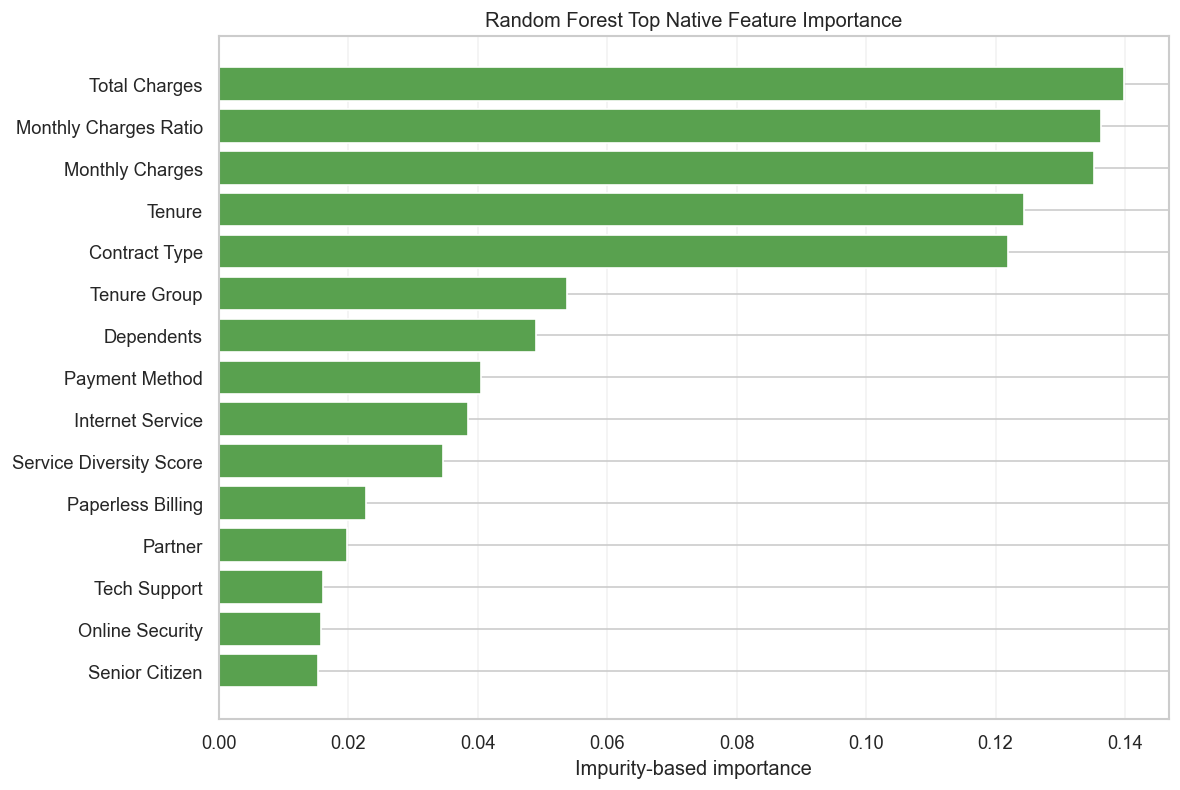

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/model_interpretation_02_random_forest_top_importance.png')

In [6]:
rf_summary = random_forest_importance.copy().sort_values('Importance', ascending=False).reset_index(drop=True)
rf_summary['Rank'] = np.arange(1, len(rf_summary) + 1)
rf_summary['Driver_Group'] = rf_summary.apply(standardize_driver_group, axis=1)
rf_output_columns = ['Feature_Code', 'Feature_Display_Name', 'Importance', 'Rank', 'Driver_Group']
random_forest_top_features = rf_summary[rf_output_columns].head(TOP_N_FEATURES).copy()
display_and_save_table(
    random_forest_top_features,
    'model_interpretation_random_forest_top_features.csv',
    'Random Forest native feature importance summary',
)
plot_horizontal_bar(
    random_forest_top_features,
    'Importance',
    'Feature_Display_Name',
    'Random Forest Top Native Feature Importance',
    'Impurity-based importance',
    'model_interpretation_02_random_forest_top_importance.png',
    color='#59A14F',
)

## 7. XGBoost Gain-Based Feature Importance Interpretation

XGBoost gain-based feature importance summary


,Feature_Code,Feature_Display_Name,Importance,Rank,Driver_Group
0,Contract,Contract Type,106.530678,1,Contract type
1,Dependents,Dependents,31.765200,2,Other customer or service profile
2,InternetService,Internet Service,25.567146,3,Internet service
3,tenure_group,Tenure Group,13.311166,4,Tenure
4,Tenure,Tenure,10.931134,5,Contract type
5,PaperlessBilling,Paperless Billing,9.441069,6,Paperless billing
6,TechSupport,Tech Support,9.205020,7,Tech support / online security
7,OnlineSecurity,Online Security,7.872219,8,Tech support / online security
8,MonthlyCharges,Monthly Charges,7.493329,9,Monthly charges / total charges
9,service_diversity,Service Diversity Score,7.201778,10,Service diversity


Table shape: (15, 5)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_xgboost_top_features.csv
Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_03_xgboost_top_importance.png


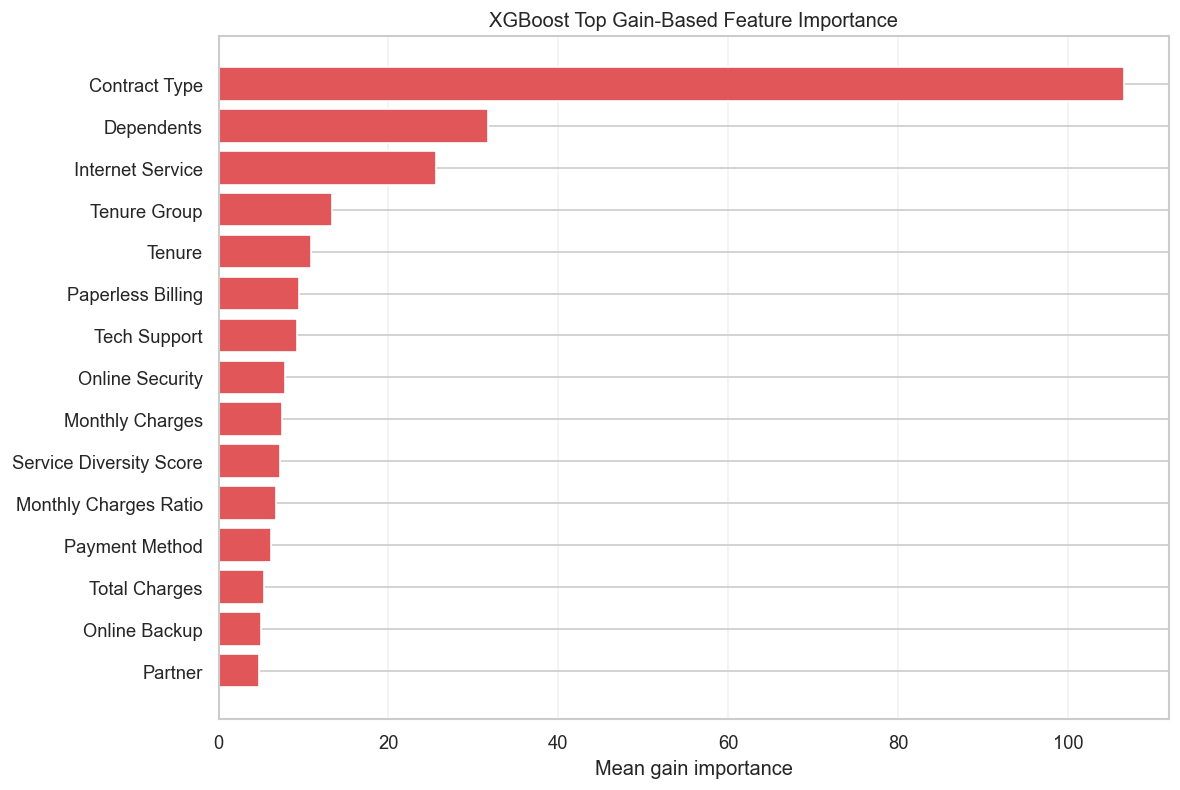

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/model_interpretation_03_xgboost_top_importance.png')

In [7]:
xgb_gain_summary = xgboost_importance.copy().sort_values('Importance', ascending=False).reset_index(drop=True)
xgb_gain_summary['Rank'] = np.arange(1, len(xgb_gain_summary) + 1)
xgb_gain_summary['Driver_Group'] = xgb_gain_summary.apply(standardize_driver_group, axis=1)
xgb_output_columns = ['Feature_Code', 'Feature_Display_Name', 'Importance', 'Rank', 'Driver_Group']
xgboost_top_features = xgb_gain_summary[xgb_output_columns].head(TOP_N_FEATURES).copy()
display_and_save_table(
    xgboost_top_features,
    'model_interpretation_xgboost_top_features.csv',
    'XGBoost gain-based feature importance summary',
)
plot_horizontal_bar(
    xgboost_top_features,
    'Importance',
    'Feature_Display_Name',
    'XGBoost Top Gain-Based Feature Importance',
    'Mean gain importance',
    'model_interpretation_03_xgboost_top_importance.png',
    color='#E15759',
)

## 8. Interpretation-Only XGBoost Model Recreation for SHAP

In [8]:
from churn_pipeline_v2.src.main import run_pipeline

result = run_pipeline(force_ingestion=False, use_database=False)
outputs = result['outputs']

tree_train = outputs['tree']['train']
tree_val = outputs['tree']['validation']
tree_test = outputs['tree']['test']

for split_name, frame in [('train', tree_train), ('validation', tree_val), ('test', tree_test)]:
    expected_shape = EXPECTED_TREE_DIMS[split_name]
    print(f'tree_{split_name} shape: {frame.shape}')
    if frame.shape != expected_shape:
        raise ValueError(f'tree_{split_name} expected {expected_shape}, got {frame.shape}')
    if 'ID' not in frame.columns or 'Churn' not in frame.columns:
        raise ValueError(f'tree_{split_name} must contain ID and Churn before X/y split.')

X_train = tree_train.drop(columns=['ID', 'Churn'])
y_train = tree_train['Churn'].astype(int)
X_val = tree_val.drop(columns=['ID', 'Churn'])
y_val = tree_val['Churn'].astype(int)
X_test = tree_test.drop(columns=['ID', 'Churn'])
y_test = tree_test['Churn'].astype(int)

for split_name, frame in [('train', X_train), ('validation', X_val), ('test', X_test)]:
    expected_shape = EXPECTED_X_DIMS[split_name]
    print(f'X_{split_name} shape: {frame.shape}')
    if frame.shape != expected_shape:
        raise ValueError(f'X_{split_name} expected {expected_shape}, got {frame.shape}')
    if 'ID' in frame.columns or 'Churn' in frame.columns:
        raise ValueError(f'X_{split_name} contains ID or Churn.')
    object_columns = frame.select_dtypes(include='object').columns.tolist()
    if object_columns:
        raise TypeError(f'X_{split_name} contains object columns: {object_columns}')

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight from y_train only: {scale_pos_weight:.6f}')

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective='binary:logistic',
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train)
print('Interpretation-only XGBoost model recreated for SHAP. No threshold tuning or model selection performed.')

2026-07-08 14:43:32,792 - main - [INFO] - Refactored churn pipeline orchestration started.
2026-07-08 14:43:32,793 - main - [INFO] - Run options: force_ingestion=False, use_database=False, view_name=None
2026-07-08 14:43:32,794 - main - [INFO] - Train checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\train_df.csv
2026-07-08 14:43:32,795 - main - [INFO] - Validation checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\validation_df.csv
2026-07-08 14:43:32,796 - main - [INFO] - Test checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\test_df.csv
2026-07-08 14:43:32,797 - main - [INFO] - All checkpoint files exist; ingestion skipped.
2026-07-08 14:43:32,814 - main - [INFO] - Loaded train checkpoint shape: (4930, 16)
2026-07-08 14:43:32,815 - main - [INFO] - Loaded validation checkpoint shape: (1056,

All required project directories are available.
All required project directories are available.


2026-07-08 14:43:33,015 - main - [INFO] - Logistic train output shape: (4930, 28)
2026-07-08 14:43:33,015 - main - [INFO] - Logistic validation output shape: (1056, 28)
2026-07-08 14:43:33,016 - main - [INFO] - Logistic test output shape: (1057, 28)
2026-07-08 14:43:33,018 - main - [INFO] - Tree train output shape: (4930, 20)
2026-07-08 14:43:33,019 - main - [INFO] - Tree validation output shape: (1056, 20)
2026-07-08 14:43:33,021 - main - [INFO] - Tree test output shape: (1057, 20)
2026-07-08 14:43:33,022 - main - [INFO] - Preprocessing branch orchestration completed.
2026-07-08 14:43:33,023 - main - [INFO] - Refactored churn pipeline orchestration finished.


tree_train shape: (4930, 20)
tree_validation shape: (1056, 20)
tree_test shape: (1057, 20)
X_train shape: (4930, 18)
X_validation shape: (1056, 18)
X_test shape: (1057, 18)
scale_pos_weight from y_train only: 2.769113
Interpretation-only XGBoost model recreated for SHAP. No threshold tuning or model selection performed.


## 9. SHAP Sample Preparation

In [9]:
sample_size = min(SHAP_SAMPLE_SIZE, len(X_val))
X_shap_sample = X_val.sample(n=sample_size, random_state=RANDOM_STATE).copy()
y_shap_sample = y_val.loc[X_shap_sample.index].copy()
validation_churn_probability = xgb_model.predict_proba(X_val)[:, 1]
high_risk_position = int(np.argmax(validation_churn_probability))
high_risk_index = X_val.index[high_risk_position]
high_risk_row = X_val.loc[[high_risk_index]].copy()
high_risk_probability = float(validation_churn_probability[high_risk_position])

feature_mapping_used = build_feature_mapping_table(X_train.columns)
feature_display_lookup = dict(zip(feature_mapping_used['Feature_Code'], feature_mapping_used['Feature_Display_Name']))
display_feature_names = [feature_display_lookup.get(column, column) for column in X_train.columns]

if list(X_train.columns) != list(X_shap_sample.columns):
    raise ValueError('SHAP sample columns do not match X_train columns.')
if len(display_feature_names) != X_train.shape[1]:
    raise ValueError('Display feature names do not align with model feature count.')

feature_mapping_used = feature_mapping_used.copy()
feature_mapping_used['Used_For_SHAP'] = True
display_and_save_table(
    feature_mapping_used,
    'model_interpretation_feature_mapping_used.csv',
    'Feature mapping used for interpretation labels',
)

print(f'SHAP sample source: validation set')
print(f'SHAP sample shape: {X_shap_sample.shape}')
print(f'High-risk validation row index: {high_risk_index}')
print(f'High-risk recreated XGBoost churn probability: {high_risk_probability:.6f}')

Feature mapping used for interpretation labels


,Feature_Code,Feature_Display_Name,Base_Feature,Base_Feature_Display_Name,Encoded_Category,Encoded_Category_Display_Name,Feature_Group,Feature_Type,Is_Encoded,Used_For_SHAP
0,SeniorCitizen,Senior Citizen,SeniorCitizen,Senior Citizen,None,None,Customer Profile,Binary,False,True
1,Partner,Partner,Partner,Partner,None,None,Customer Profile,Binary,False,True
2,Dependents,Dependents,Dependents,Dependents,None,None,Customer Profile,Binary,False,True
3,Tenure,Tenure,Tenure,Tenure,None,None,Account / Contract,Numeric,False,True
4,Contract,Contract Type,Contract,Contract Type,None,None,Account / Contract,Categorical,False,True
5,PaymentMethod,Payment Method,PaymentMethod,Payment Method,None,None,Billing,Categorical,False,True
6,PaperlessBilling,Paperless Billing,PaperlessBilling,Paperless Billing,None,None,Billing,Binary,False,True
7,MonthlyCharges,Monthly Charges,MonthlyCharges,Monthly Charges,None,None,Charges,Numeric,False,True
8,TotalCharges,Total Charges,TotalCharges,Total Charges,None,None,Charges,Numeric,False,True
9,InternetService,Internet Service,InternetService,Internet Service,None,None,Service,Categorical,False,True


Table shape: (18, 10)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_feature_mapping_used.csv
SHAP sample source: validation set
SHAP sample shape: (500, 18)
High-risk validation row index: 459
High-risk recreated XGBoost churn probability: 0.978881


## 10. SHAP Value Computation

In [10]:
explainer = shap.TreeExplainer(xgb_model)
shap_explanation_raw = explainer(X_shap_sample)

if shap_explanation_raw.values.shape[1] != X_train.shape[1]:
    raise ValueError('SHAP value feature dimension does not match X_train.')

X_shap_display = X_shap_sample.copy()
X_shap_display.columns = display_feature_names
shap_explanation_display = shap.Explanation(
    values=shap_explanation_raw.values,
    base_values=shap_explanation_raw.base_values,
    data=X_shap_display.values,
    feature_names=display_feature_names,
)

high_risk_shap_raw = explainer(high_risk_row)
high_risk_display = high_risk_row.copy()
high_risk_display.columns = display_feature_names
high_risk_explanation_display = shap.Explanation(
    values=high_risk_shap_raw.values[0],
    base_values=high_risk_shap_raw.base_values[0],
    data=high_risk_display.iloc[0].values,
    feature_names=display_feature_names,
)

print(f'SHAP values shape: {shap_explanation_raw.values.shape}')
print(f'SHAP expected value sample shape: {np.shape(shap_explanation_raw.base_values)}')

ValueError: could not convert string to float: '[5E-1]'

## 11. SHAP Mean Absolute Importance Table

In [ ]:
mean_abs_shap = np.abs(shap_explanation_raw.values).mean(axis=0)
shap_importance = pd.DataFrame({
    'Feature_Code': X_train.columns,
    'Feature_Display_Name': display_feature_names,
    'Mean_Abs_SHAP': mean_abs_shap,
    'Model': 'XGBoost',
})
shap_importance = shap_importance.sort_values('Mean_Abs_SHAP', ascending=False).reset_index(drop=True)
shap_importance['Rank'] = np.arange(1, len(shap_importance) + 1)
shap_importance['Driver_Group'] = shap_importance.apply(standardize_driver_group, axis=1)
shap_importance = shap_importance[['Feature_Code', 'Feature_Display_Name', 'Mean_Abs_SHAP', 'Rank', 'Model', 'Driver_Group']]
display_and_save_table(
    shap_importance,
    'model_interpretation_xgboost_shap_mean_abs.csv',
    'XGBoost SHAP mean absolute importance',
)

## 12. SHAP Summary Bar Plot

In [ ]:
plt.figure(figsize=(9, 7))
shap.plots.bar(shap_explanation_display, max_display=TOP_N_FEATURES, show=False)
plt.title('XGBoost SHAP Summary - Mean Absolute Impact')
save_current_figure('model_interpretation_04_xgboost_shap_summary_bar.png', tight=False)

## 13. SHAP Beeswarm Plot

In [ ]:
plt.figure(figsize=(10, 8))
shap.plots.beeswarm(shap_explanation_display, max_display=TOP_N_FEATURES, show=False)
plt.title('XGBoost SHAP Beeswarm - Validation Sample')
save_current_figure('model_interpretation_05_xgboost_shap_beeswarm.png', tight=False)

## 14. SHAP Dependence Plot for Top Feature

In [ ]:
top_shap_feature_code = shap_importance.loc[0, 'Feature_Code']
top_shap_feature_display = shap_importance.loc[0, 'Feature_Display_Name']
top_shap_feature_index = list(X_train.columns).index(top_shap_feature_code)

plt.figure(figsize=(9, 6))
shap.dependence_plot(
    top_shap_feature_index,
    shap_explanation_raw.values,
    X_shap_display,
    feature_names=display_feature_names,
    show=False,
    interaction_index=None,
)
plt.title(f'SHAP Dependence - {top_shap_feature_display}')
save_current_figure('model_interpretation_06_xgboost_shap_dependence_top_feature.png', tight=False)

## 15. SHAP Waterfall Plot for One High-Risk Customer

In [ ]:
plt.figure(figsize=(10, 7))
shap.plots.waterfall(high_risk_explanation_display, max_display=TOP_N_FEATURES, show=False)
plt.title(f'XGBoost SHAP Waterfall - High-Risk Validation Customer (p={high_risk_probability:.3f})')
save_current_figure('model_interpretation_07_xgboost_shap_waterfall_high_risk_customer.png', tight=False)

## 16. Top Business Drivers Summary

In [ ]:
logistic_driver_rows = logistic_coefficients_summary.head(10).copy()
logistic_driver_rows['Method_Value'] = logistic_driver_rows['Abs_Coefficient']
business_driver_tables = [
    build_business_driver_rows(logistic_driver_rows, 'Logistic coefficients', 'Method_Value', 'absolute coefficient', top_n=10),
    build_business_driver_rows(random_forest_top_features, 'Random Forest native importance', 'Importance', 'impurity importance', top_n=10),
    build_business_driver_rows(xgboost_top_features, 'XGBoost gain importance', 'Importance', 'mean gain', top_n=10),
    build_business_driver_rows(shap_importance, 'XGBoost SHAP mean absolute impact', 'Mean_Abs_SHAP', 'mean absolute SHAP', top_n=10),
]
top_business_drivers = pd.concat(business_driver_tables, ignore_index=True)
display_and_save_table(
    top_business_drivers,
    'model_interpretation_top_business_drivers.csv',
    'Top business drivers across interpretation methods',
)

common_driver_summary = (
    top_business_drivers.groupby('Driver_Group')['Method']
    .nunique()
    .reset_index(name='Method_Count')
    .sort_values(['Method_Count', 'Driver_Group'], ascending=[False, True])
)
display(common_driver_summary)

## 17. Save CSV Outputs

In [ ]:
expected_csv_outputs = [
    'model_interpretation_logistic_coefficients_summary.csv',
    'model_interpretation_random_forest_top_features.csv',
    'model_interpretation_xgboost_top_features.csv',
    'model_interpretation_xgboost_shap_mean_abs.csv',
    'model_interpretation_top_business_drivers.csv',
    'model_interpretation_feature_mapping_used.csv',
]
csv_output_check = pd.DataFrame([
    {'File': filename, 'Path': DATA_REPORTS_DIR / filename, 'Created': (DATA_REPORTS_DIR / filename).exists()}
    for filename in expected_csv_outputs
])
display(csv_output_check)
if not csv_output_check['Created'].all():
    missing = csv_output_check.loc[~csv_output_check['Created'], 'File'].tolist()
    raise FileNotFoundError(f'Missing expected interpretation CSV outputs: {missing}')

## 18. Save Figure Outputs

In [ ]:
expected_figure_outputs = [
    'model_interpretation_01_logistic_top_coefficients.png',
    'model_interpretation_02_random_forest_top_importance.png',
    'model_interpretation_03_xgboost_top_importance.png',
    'model_interpretation_04_xgboost_shap_summary_bar.png',
    'model_interpretation_05_xgboost_shap_beeswarm.png',
    'model_interpretation_06_xgboost_shap_dependence_top_feature.png',
    'model_interpretation_07_xgboost_shap_waterfall_high_risk_customer.png',
]
figure_output_check = pd.DataFrame([
    {'File': filename, 'Path': FIGURES_DIR / filename, 'Created': (FIGURES_DIR / filename).exists()}
    for filename in expected_figure_outputs
])
display(figure_output_check)
if not figure_output_check['Created'].all():
    missing = figure_output_check.loc[~figure_output_check['Created'], 'File'].tolist()
    raise FileNotFoundError(f'Missing expected interpretation figures: {missing}')

## 19. Source Safety Confirmation

In [ ]:
print('Notebook 06 source safety confirmation')
print('run_pipeline call uses force_ingestion=False and use_database=False for interpretation-only XGBoost recreation.')
print('No threshold tuning, model selection, or metric comparison is performed in this notebook.')
print('No recreated model artifact is saved.')
print('No source files, preprocessing files, SQL files, checkpoints, or existing notebooks are modified by notebook code.')
print('New outputs are limited to model_interpretation_* CSV and figure files.')

## 20. Final Interpretation Summary

In [ ]:
balanced_model = best_model_summary.loc[best_model_summary['Criterion'] == 'Recommended_Balanced_Model', 'Model'].iloc[0]
recall_focused_model = best_model_summary.loc[best_model_summary['Criterion'] == 'Recommended_Recall_Focused_Model', 'Model'].iloc[0]

top_positive_logistic = logistic_coefficients_summary[logistic_coefficients_summary['Coefficient'] > 0].head(5)
top_negative_logistic = logistic_coefficients_summary[logistic_coefficients_summary['Coefficient'] < 0].head(5)
top_rf = random_forest_top_features.head(5)
top_xgb_gain = xgboost_top_features.head(5)
top_shap = shap_importance.head(5)

print('Final interpretation summary')
print(f'- Notebook 05 balanced model: {balanced_model}')
print(f'- Notebook 05 recall-focused model: {recall_focused_model}')
print('- Logistic Regression top positive churn drivers:')
print(top_positive_logistic['Feature_Display_Name'].tolist())
print('- Logistic Regression top negative churn drivers:')
print(top_negative_logistic['Feature_Display_Name'].tolist())
print('- Random Forest top native importance drivers:')
print(top_rf['Feature_Display_Name'].tolist())
print('- XGBoost top gain-importance drivers:')
print(top_xgb_gain['Feature_Display_Name'].tolist())
print('- XGBoost top SHAP drivers:')
print(top_shap['Feature_Display_Name'].tolist())
print('- Common business driver groups appearing across interpretation methods:')
print(common_driver_summary.head(8)['Driver_Group'].tolist())
print('SHAP explains the recreated XGBoost model for interpretation only; it does not change model selection or Notebook 05 results.')